# Data Preprocessing

This notebook focuses on cleaning and preparing the used car dataset for machine learning.

### Objectives
- Remove unnecessary columns.
- Handle missing and invalid values.
- Convert object columns into numerical format.
- Perform feature engineering.
- Prepare the dataset for model training.

In [1]:
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../data/raw/train-data.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (6019, 14)


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [3]:
clean_df = df.copy()

In [4]:
(clean_df['Unnamed: 0'].to_numpy() == np.arange(len(clean_df))).all()

np.True_

In [5]:
clean_df.drop(columns=['Unnamed: 0'], inplace=True)
clean_df.shape

(6019, 13)

In [6]:
clean_df['Brand'] = clean_df['Name'].apply(
    lambda name: 'Land Rover' if name.startswith('Land Rover')
    else name.split()[0]
)
clean_df['Brand'] = clean_df['Brand'].str.title()  #iSUZU  isuzu

clean_df['Brand'].value_counts().head(25)

Brand
Maruti           1211
Hyundai          1107
Honda             608
Toyota            411
Mercedes-Benz     318
Volkswagen        315
Ford              300
Mahindra          272
Bmw               267
Audi              236
Tata              186
Skoda             173
Renault           145
Chevrolet         121
Nissan             91
Land Rover         60
Jaguar             40
Fiat               28
Mitsubishi         27
Mini               26
Volvo              21
Porsche            18
Jeep               15
Datsun             13
Isuzu               3
Name: count, dtype: int64

In [7]:
clean_df['Mileage'] = pd.to_numeric(
    clean_df['Mileage']
    .str.replace(' kmpl', '', regex=False)
    .str.replace(' km/kg', '', regex=False),
    errors='coerce'
)

In [8]:
clean_df['Engine'] = pd.to_numeric(
    clean_df['Engine'].str.replace(' CC', '', regex=False),
    errors='coerce'
)

In [9]:
clean_df['Power'] = pd.to_numeric(
    clean_df['Power']
    .str.replace(' bhp', '', regex=False),
    errors='coerce'
)

In [10]:
clean_df[['Mileage', 'Engine', 'Power']].info()

clean_df[['Mileage', 'Engine', 'Power']].head(10)

<class 'pandas.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Mileage  6017 non-null   float64
 1   Engine   5983 non-null   float64
 2   Power    5876 non-null   float64
dtypes: float64(3)
memory usage: 141.2 KB


,Mileage,Engine,Power
0,26.60,998.0,58.16
1,19.67,1582.0,126.20
2,18.20,1199.0,88.70
3,20.77,1248.0,88.76
4,15.20,1968.0,140.80
5,21.10,814.0,55.20
6,23.08,1461.0,63.10
7,11.36,2755.0,171.50
8,20.54,1598.0,103.60
9,22.30,1248.0,74.00


In [11]:
print("Zero Mileage:", (clean_df['Mileage'] == 0).sum())

print("Zero Engine:", (clean_df['Engine'] == 0).sum())

print("Zero Power:", (clean_df['Power'] == 0).sum())

print("Zero Seats:", (clean_df['Seats'] == 0).sum())

Zero Mileage: 68
Zero Engine: 0
Zero Power: 0
Zero Seats: 1


In [12]:
clean_df['Mileage'] = clean_df['Mileage'].replace(0, np.nan)

clean_df['Seats'] = clean_df['Seats'].replace(0, np.nan)

In [13]:
print("Mileage zeros:", (clean_df['Mileage'] == 0).sum())
print("Seats zeros:", (clean_df['Seats'] == 0).sum())

print("\nMissing values:")
print(clean_df[['Mileage', 'Engine', 'Power', 'Seats']].isnull().sum())

Mileage zeros: 0
Seats zeros: 0

Missing values:
Mileage     70
Engine      36
Power      143
Seats       43
dtype: int64


In [14]:
missing_summary = pd.DataFrame({
    'Missing Values': clean_df.isnull().sum(),
    'Percentage': (clean_df.isnull().mean() * 100).round(2)
})

missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Percentage
Mileage,70,1.16
Engine,36,0.60
Power,143,2.38
Seats,43,0.71
New_Price,5195,86.31


In [15]:
clean_df.drop(columns=['New_Price'], inplace=True)
clean_df.shape

(6019, 13)

In [16]:
clean_df.nlargest(10, 'Kilometers_Driven')[
    ['Name', 'Year', 'Kilometers_Driven', 'Price']
]

,Name,Year,Kilometers_Driven,Price
2328,BMW X5 xDrive 30d M Sport,2017,6500000,65.00
340,Skoda Octavia Ambition Plus 2.0 TDI AT,2013,775000,7.50
1860,Volkswagen Vento Diesel Highline,2013,720000,5.90
358,Hyundai i10 Magna 1.2,2009,620000,2.70
2823,Volkswagen Jetta 2013-2015 2.0L TDI Highline AT,2015,480000,13.00
3092,Honda City i VTEC SV,2015,480000,5.00
4491,Hyundai i20 Magna Optional 1.2,2013,445000,4.45
3649,Tata Indigo LS,2008,300000,1.00
1528,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,2005,299322,4.00
1975,Skoda Superb 1.8 TSI MT,2012,282000,3.30


### Kilometers Driven - Outlier Investigation

- Several vehicles were found with unusually high kilometre readings.
- The highest value was 6,500,000 km for a 2017 BMW X5.
- Other records also showed mileage values above 600,000 km.
- These values may represent data-entry errors or genuine high-mileage vehicles.
- No records were deleted or modified without verification.
- Their impact will be evaluated during model development.

In [17]:
categorical_cols = clean_df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(clean_df[col].value_counts())


Name:
Name
Mahindra XUV500 W8 2WD                        49
Maruti Swift VDI                              45
Honda City 1.5 S MT                           34
Maruti Swift Dzire VDI                        34
Maruti Swift VDI BSIV                         31
                                              ..
Hyundai Elantra SX                             1
Maruti Wagon R Duo Lxi                         1
Volkswagen Polo IPL II 1.2 Petrol Highline     1
Tata Bolt Revotron XT                          1
Mahindra Xylo D4 BSIV                          1
Name: count, Length: 1876, dtype: int64

Location:
Location
Mumbai        790
Hyderabad     742
Kochi         651
Coimbatore    636
Pune          622
Delhi         554
Kolkata       535
Chennai       494
Jaipur        413
Bangalore     358
Ahmedabad     224
Name: count, dtype: int64

Fuel_Type:
Fuel_Type
Diesel      3205
Petrol      2746
CNG           56
LPG           10
Electric       2
Name: count, dtype: int64

Transmission:
Transmission
Manu

C:\Users\sreer\AppData\Local\Temp\ipykernel_2844\183114181.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = clean_df.select_dtypes(include='object').columns


In [18]:
clean_df['Brand'] = clean_df['Brand'].replace({
    'Bmw': 'BMW'
})

In [19]:
print("Dataset shape:", clean_df.shape)

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nData types:")
print(clean_df.dtypes)

Dataset shape: (6019, 13)

Missing values:
Name                   0
Location               0
Year                   0
Kilometers_Driven      0
Fuel_Type              0
Transmission           0
Owner_Type             0
Mileage               70
Engine                36
Power                143
Seats                 43
Price                  0
Brand                  0
dtype: int64

Data types:
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage              float64
Engine               float64
Power                float64
Seats                float64
Price                float64
Brand                    str
dtype: object


In [20]:
# Remove the suspicious Porsche record
clean_df = clean_df.drop(index=3132)

print("Updated dataset shape:", clean_df.shape)

Updated dataset shape: (6018, 13)


In [21]:
X = clean_df.drop(columns=['Price'])
y = clean_df['Price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6018, 12)
Target shape: (6018,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4814, 12)
Testing data: (1204, 12)


In [23]:
numeric_features = X_train.select_dtypes(include='number').columns.tolist()

categorical_features = X_train.select_dtypes(include='str').columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


Numerical features: ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats']

Categorical features: ['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Brand']


In [24]:
from sklearn.impute import SimpleImputer

numeric_imputer = SimpleImputer(strategy='median')

In [25]:
X_train_numeric = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

In [26]:
X_test_numeric = numeric_imputer.transform(
    X_test[numeric_features]
)

In [27]:
print("Training missing values:", np.isnan(X_train_numeric).sum())
print("Testing missing values:", np.isnan(X_test_numeric).sum())

Training missing values: 0
Testing missing values: 0


Categorical feature encoding


In [28]:
# exclude name  

categorical_features = [
    'Location',
    'Fuel_Type',
    'Transmission',
    'Owner_Type',
    'Brand'
]



In [29]:
from sklearn.impute import SimpleImputer

categorical_imputer = SimpleImputer(strategy='most_frequent')

X_train_cat = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

X_test_cat = categorical_imputer.transform(
    X_test[categorical_features]
)

In [30]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train_cat)

X_test_encoded = encoder.transform(X_test_cat)

In [31]:
print("Training categorical shape:", X_train_encoded.shape)
print("Testing categorical shape:", X_test_encoded.shape)

Training categorical shape: (4814, 50)
Testing categorical shape: (1204, 50)


Combine Numerical and Categorical Features

In [32]:
X_train_processed = np.hstack([
    X_train_numeric,
    X_train_encoded
])

In [33]:
X_test_processed = np.hstack([
    X_test_numeric,
    X_test_encoded
])

In [34]:
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (4814, 56)
Processed testing shape: (1204, 56)


In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [36]:
lr_model = LinearRegression()

lr_model.fit(X_train_processed, y_train)
y_pred_lr = lr_model.predict(X_test_processed)

In [37]:
mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print("------------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Linear Regression Performance
------------------------------
MAE: 3.05
RMSE: 6.1
R2 Score: 0.7378


In [38]:
from sklearn.ensemble import RandomForestRegressor

In [39]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [40]:
y_pred_rf = rf_model.predict(X_test_processed)

In [41]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print("MAE:", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R2 Score:", round(r2_rf, 4))

Random Forest Performance
-------------------------
MAE: 1.51
RMSE: 4.5
R2 Score: 0.8574


In [42]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae, mae_rf],
    'RMSE': [rmse, rmse_rf],
    'R2 Score': [r2, r2_rf]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.049433,6.096328,0.737809
1,Random Forest,1.513389,4.496434,0.857368


# Overfit check

In [43]:
# Predict on training data
y_train_pred_rf = rf_model.predict(X_train_processed)

# Calculate training performance
train_mae_rf = mean_absolute_error(y_train, y_train_pred_rf)
train_r2_rf = r2_score(y_train, y_train_pred_rf)

# Calculate testing performance
test_mae_rf = mean_absolute_error(y_test, y_pred_rf)
test_r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest - Training Performance")
print("-------------------------------------")
print("MAE:", round(train_mae_rf, 2))
print("R2 Score:", round(train_r2_rf, 4))

print("\nRandom Forest - Testing Performance")
print("-----------------------------------")
print("MAE:", round(test_mae_rf, 2))
print("R2 Score:", round(test_r2_rf, 4))

Random Forest - Training Performance
-------------------------------------
MAE: 0.53
R2 Score: 0.9876

Random Forest - Testing Performance
-----------------------------------
MAE: 1.51
R2 Score: 0.8574


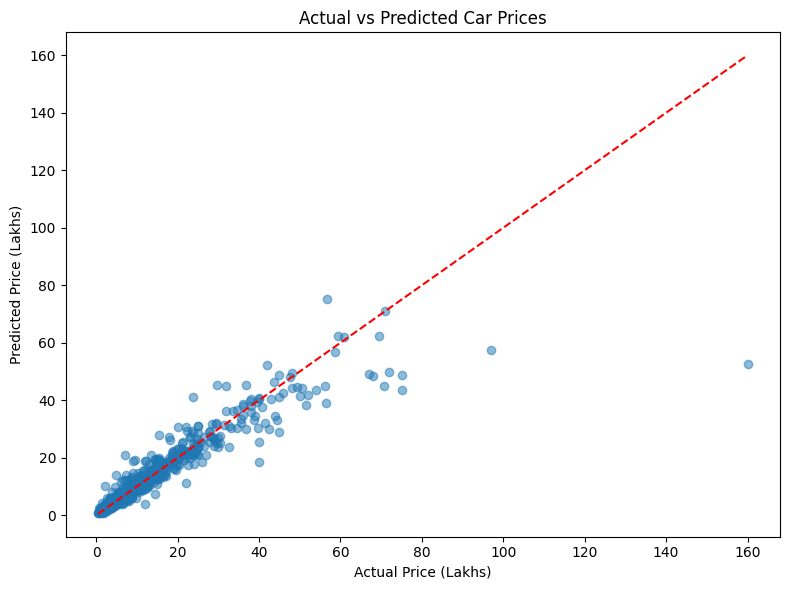

In [44]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.5)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Car Prices")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.tight_layout()
plt.show()

In [45]:
prediction_results = pd.DataFrame({
    'Car_Name': X_test['Name'],
    'Actual_Price': y_test,
    'Predicted_Price': y_pred_rf
})

prediction_results['Absolute_Error'] = abs(
    prediction_results['Actual_Price'] -
    prediction_results['Predicted_Price']
)

prediction_results = prediction_results.sort_values(
    by='Absolute_Error',
    ascending=False
)

prediction_results.head(10)

,Car_Name,Actual_Price,Predicted_Price,Absolute_Error
4079,Land Rover Range Rover 3.0 Diesel LWB Vogue,160.00,52.75395,107.24605
1505,Land Rover Range Rover Sport SE,97.07,57.53030,39.53970
655,Jaguar XJ 2.0L Portfolio,75.00,43.73525,31.26475
3489,Porsche Panamera Diesel,75.00,48.75745,26.24255
3752,Land Rover Range Rover Sport HSE,70.66,44.87320,25.78680
5603,Porsche Panamera 2010 2013 Diesel,72.00,49.84310,22.15690
926,Porsche Cayman 2009-2012 S,40.00,18.43750,21.56250
5009,Audi Q7 45 TDI Quattro Technology,68.00,48.58970,19.41030
4451,Ford Mustang V8,56.80,75.33030,18.53030
1038,Land Rover Range Rover TDV8 (Diesel),67.00,48.95815,18.04185


In [46]:
porsche_cars = clean_df[
    clean_df['Brand'] == 'Porsche'
][
    ['Name', 'Year', 'Kilometers_Driven', 'Engine', 'Power', 'Price']
].sort_values('Price', ascending=False)

porsche_cars

,Name,Year,Kilometers_Driven,Engine,Power,Price
2659,Porsche Panamera Diesel,2015,25100,2967.0,300.0,75.00
3489,Porsche Panamera Diesel,2013,19828,2967.0,300.0,75.00
5603,Porsche Panamera 2010 2013 Diesel,2013,36400,4806.0,394.3,72.00
5341,Porsche Cayenne S Diesel,2016,65003,4134.0,382.0,67.83
1078,Porsche Boxster S tiptronic,2015,10512,2706.0,265.0,64.00
4185,Porsche Panamera Diesel,2015,54996,2967.0,300.0,60.95
2706,Porsche Panamera Diesel 250hp,2014,60033,2967.0,250.0,51.52
2896,Porsche Panamera Diesel,2013,48000,2967.0,300.0,50.50
5512,Porsche Cayenne 2009-2014 Diesel,2015,47877,2967.0,240.0,48.22
4377,Porsche Cayenne Diesel,2015,60395,2967.0,245.0,45.82


### Handling Suspicious Price Records

During prediction error analysis, a suspicious Porsche Cayenne record was identified.

The vehicle was a 2019 model with only 14,298 km driven, but its recorded price was just ₹2.02 lakhs. This value was inconsistent with other Porsche records in the dataset.

Since the target value appeared highly unreliable, the record was excluded from the cleaned dataset. The original raw dataset remains unchanged.

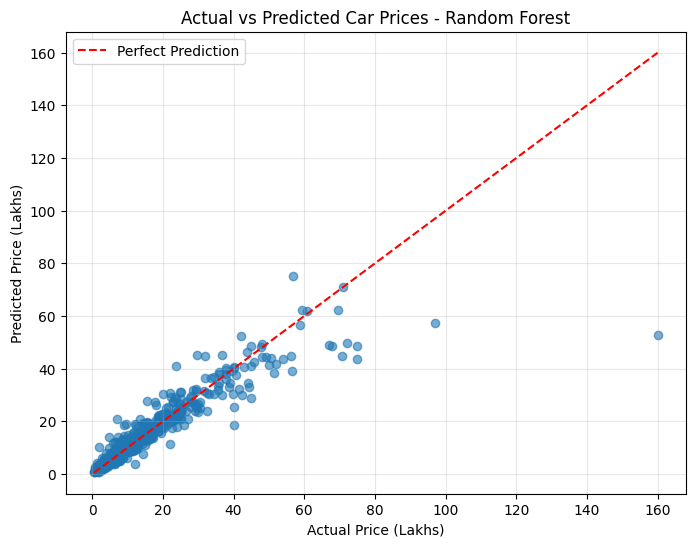

In [47]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.6)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred_rf.min())
max_price = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Car Prices - Random Forest")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Actual vs Predicted Price Analysis

- Most predictions are reasonably close to the actual prices.
- The model performs better for cars in the lower and middle price ranges.
- Larger prediction errors are observed for expensive luxury cars.
- The model tends to underestimate some high-priced vehicles.
- This may be due to the limited number of expensive cars in the dataset.

Overall, the Random Forest model shows good predictive performance,
but its accuracy can be improved for high-priced vehicles.

In [48]:
# Create a DataFrame for prediction error analysis
error_analysis = X_test[['Name', 'Year', 'Kilometers_Driven']].copy()

error_analysis['Actual_Price'] = y_test
error_analysis['Predicted_Price'] = y_pred_rf

error_analysis['Absolute_Error'] = abs(
    error_analysis['Actual_Price'] - error_analysis['Predicted_Price']
)

# Display the 10 cars with the highest prediction errors
top_errors = error_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
).head(10)

top_errors.round(2)

,Name,Year,Kilometers_Driven,Actual_Price,Predicted_Price,Absolute_Error
4079,Land Rover Range Rover 3.0 Diesel LWB Vogue,2017,25000,160.00,52.75,107.25
1505,Land Rover Range Rover Sport SE,2019,26013,97.07,57.53,39.54
655,Jaguar XJ 2.0L Portfolio,2017,10501,75.00,43.74,31.26
3489,Porsche Panamera Diesel,2013,19828,75.00,48.76,26.24
3752,Land Rover Range Rover Sport HSE,2015,38467,70.66,44.87,25.79
5603,Porsche Panamera 2010 2013 Diesel,2013,36400,72.00,49.84,22.16
926,Porsche Cayman 2009-2012 S,2010,10000,40.00,18.44,21.56
5009,Audi Q7 45 TDI Quattro Technology,2017,59500,68.00,48.59,19.41
4451,Ford Mustang V8,2018,21290,56.80,75.33,18.53
1038,Land Rover Range Rover TDV8 (Diesel),2011,55000,67.00,48.96,18.04


### Prediction Error Analysis

- The largest prediction error was observed for a 2017 Land Rover Range Rover.
- The actual price was ₹160 lakhs, whereas the model predicted ₹52.75 lakhs.
- Most large prediction errors were associated with luxury car brands such as Land Rover, Porsche, Jaguar and Audi.
- The model tends to underestimate the prices of several expensive vehicles.
- However, some vehicles, such as the Ford Mustang, were overestimated.
- This indicates that the model performs better on common price ranges than on expensive luxury vehicles.

The limited representation of high-priced cars may be one reason for these prediction errors.

In [49]:
# Combine training features and target for analysis
train_analysis = X_train[['Brand', 'Name']].copy()
train_analysis['Price'] = y_train

# Count cars priced above 50 lakhs
expensive_cars = train_analysis[train_analysis['Price'] > 50]

print("Cars above 50 lakhs:", len(expensive_cars))

print("\nBrand-wise count:")
print(expensive_cars['Brand'].value_counts())

print("\nPrice range:")
print(expensive_cars['Price'].describe())

Cars above 50 lakhs: 70

Brand-wise count:
Brand
Mercedes-Benz    25
BMW              13
Land Rover       10
Audi              9
Porsche           6
Jaguar            5
Lamborghini       1
Bentley           1
Name: count, dtype: int64

Price range:
count     70.000000
mean      63.983143
std       13.378845
min       50.220000
25%       55.000000
50%       59.860000
75%       69.735000
max      120.000000
Name: Price, dtype: float64


In [50]:
print("TRAINING DATA")
print("Cars above 50 lakhs:", (y_train > 50).sum())
print("Maximum price:", y_train.max())

print("\nTESTING DATA")
print("Cars above 50 lakhs:", (y_test > 50).sum())
print("Maximum price:", y_test.max())

TRAINING DATA
Cars above 50 lakhs: 70
Maximum price: 120.0

TESTING DATA
Cars above 50 lakhs: 20
Maximum price: 160.0


In [51]:
print("Clean dataset:", clean_df.shape)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("3132 in clean_df:", 3132 in clean_df.index)
print("3132 in X_test:", 3132 in X_test.index)

Clean dataset: (6018, 13)
Training: (4814, 12)
Testing: (1204, 12)
3132 in clean_df: False
3132 in X_test: False


In [52]:
baseline_results = {
    'Model': 'Random Forest (Baseline)',
    'Training MAE': mean_absolute_error(y_train, y_train_pred_rf),
    'Testing MAE': mean_absolute_error(y_test, y_pred_rf),
    'Training R2': r2_score(y_train, y_train_pred_rf),
    'Testing R2': r2_score(y_test, y_pred_rf)
}

baseline_results

{'Model': 'Random Forest (Baseline)',
 'Training MAE': 0.5260139428155974,
 'Testing MAE': 1.5133888222789116,
 'Training R2': 0.9875577321223681,
 'Testing R2': 0.8573679176573074}

In [53]:
baseline_df = pd.DataFrame([baseline_results])

baseline_df.to_csv(
    '../outputs/baseline_results.csv',
    index=False
)

pd.read_csv('../outputs/baseline_results.csv')

,Model,Training MAE,Testing MAE,Training R2,Testing R2
0,Random Forest (Baseline),0.526014,1.513389,0.987558,0.857368


# Hyper Parameter Tunning


In [54]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [55]:
param_dist = {
    'n_estimators': randint(100, 500),
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': randint(2, 15),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 'log2', 1.0]
}

In [56]:
rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [57]:
rf_random.fit(X_train_processed, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 15, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': <scipy.stats....002B12FD46D10>, 'min_samples_split': <scipy.stats....002B12FCEA450>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for

In [58]:
best_rf = rf_random.best_estimator_

y_pred_tuned = best_rf.predict(X_test_processed)
y_train_pred_tuned = best_rf.predict(X_train_processed)

In [59]:

tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)

Tuned Random Forest Performance
--------------------------------
MAE: 1.675337402621181
RMSE: 4.67523300681558
R2 Score: 0.845798929138609


In [60]:
comparison = pd.DataFrame({
    'Model': ['Baseline Random Forest', 'Tuned Random Forest'],
    'MAE': [1.5134, tuned_mae],
    'RMSE': [4.5000, tuned_rmse],
    'R2 Score': [0.8574, tuned_r2]
})

comparison.to_csv('../outputs/model_comparison.csv', index=False)

comparison

,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,1.513400,4.500000,0.857400
1,Tuned Random Forest,1.675337,4.675233,0.845799


In [61]:
y_train_pred_tuned = best_rf.predict(X_train_processed)

print("Tuned Model - Training vs Testing")
print("----------------------------------")

print("Training MAE:",
      mean_absolute_error(y_train, y_train_pred_tuned))

print("Testing MAE:",
      mean_absolute_error(y_test, y_pred_tuned))

print("Training R2:",
      r2_score(y_train, y_train_pred_tuned))

print("Testing R2:",
      r2_score(y_test, y_pred_tuned))

Tuned Model - Training vs Testing
----------------------------------
Training MAE: 1.1157484853227944
Testing MAE: 1.675337402621181
Training R2: 0.9490163140137822
Testing R2: 0.845798929138609


In [62]:
# Get numerical feature names
numeric_feature_names = numeric_features

# Get encoded categorical feature names
encoded_feature_names = encoder.get_feature_names_out(categorical_features)

# Combine all feature names
all_feature_names = list(numeric_feature_names) + list(encoded_feature_names)

# Get feature importance from Random Forest
importances = rf_model.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
})

# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

feature_importance_df.head(15)

,Feature,Importance
4,Power,0.670746
0,Year,0.153175
1,Kilometers_Driven,0.043687
3,Engine,0.036181
2,Mileage,0.022114
42,Brand_Land Rover,0.017406
5,Seats,0.007190
45,Brand_Mercedes-Benz,0.004757
46,Brand_Mini,0.004198
23,Transmission_Manual,0.003752


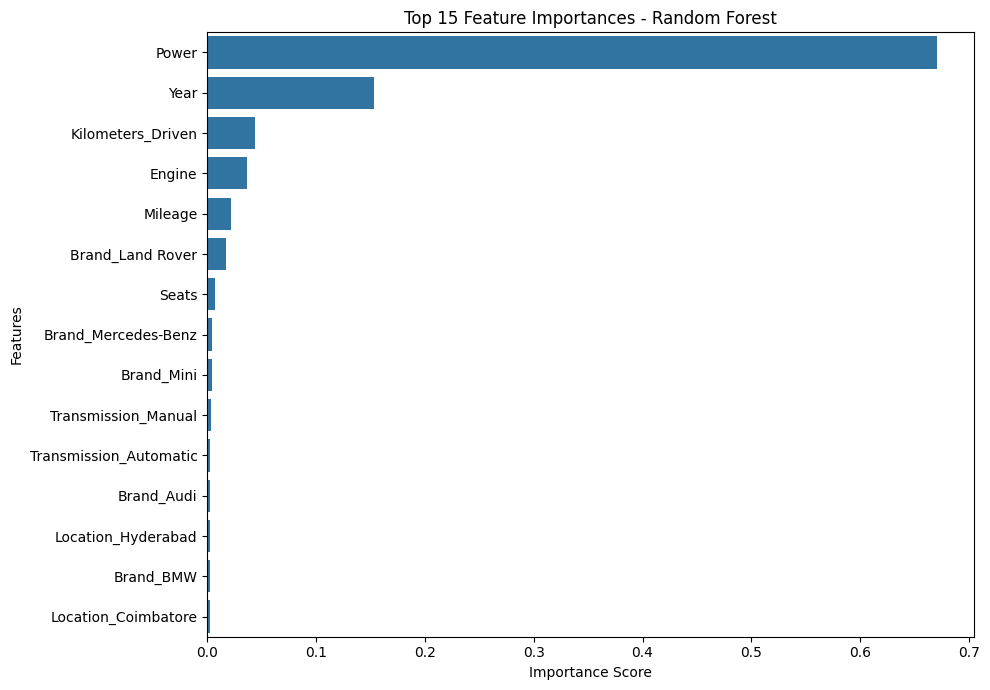

In [63]:
import seaborn as sns
plt.figure(figsize=(10, 7))

top_features = feature_importance_df.head(15)

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [64]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
perm_result = permutation_importance(
    rf_model,
    X_test_processed,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# Create DataFrame
permutation_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': perm_result.importances_mean
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

permutation_df.head(15)

,Feature,Importance
4,Power,4.865659
0,Year,2.403647
3,Engine,0.869037
1,Kilometers_Driven,0.288881
2,Mileage,0.216476
42,Brand_Land Rover,0.163482
29,Brand_BMW,0.095533
45,Brand_Mercedes-Benz,0.060102
46,Brand_Mini,0.055116
11,Location_Hyderabad,0.049322


### Feature Importance Analysis - Observations

- Power was identified as the most important feature in both importance analysis methods.
- Year was the second most influential feature.
- Engine capacity and Kilometers Driven also contributed to price prediction.
- Mileage showed relatively lower importance.
- Brand and location features had comparatively smaller individual contributions.
- Both methods consistently identified Power and Year as the dominant predictive features.

The analysis suggests that vehicle performance specifications and manufacturing year play major roles in predicting used car prices.

Note: Feature importance indicates predictive contribution, not causation.

### Actual vs Predicted Price - Observations

1. The model performs relatively well for cars priced between 0 and 30 lakhs, where most predictions are close to the ideal reference line.

2. The model struggles to predict expensive luxury cars accurately.

3. High-value cars are generally underestimated. For example:
   - A car priced around ₹100 lakhs is predicted below ₹60 lakhs.
   - A car priced around ₹160 lakhs is predicted around ₹53 lakhs.

4. Prediction errors appear to increase as actual car prices increase.

5. The model performs better for commonly occurring price ranges but struggles with expensive cars, possibly due to the limited number of high-value vehicles in the dataset.

Overall, the model provides reasonable predictions for common used cars but has limitations when predicting luxury and high-priced vehicles.

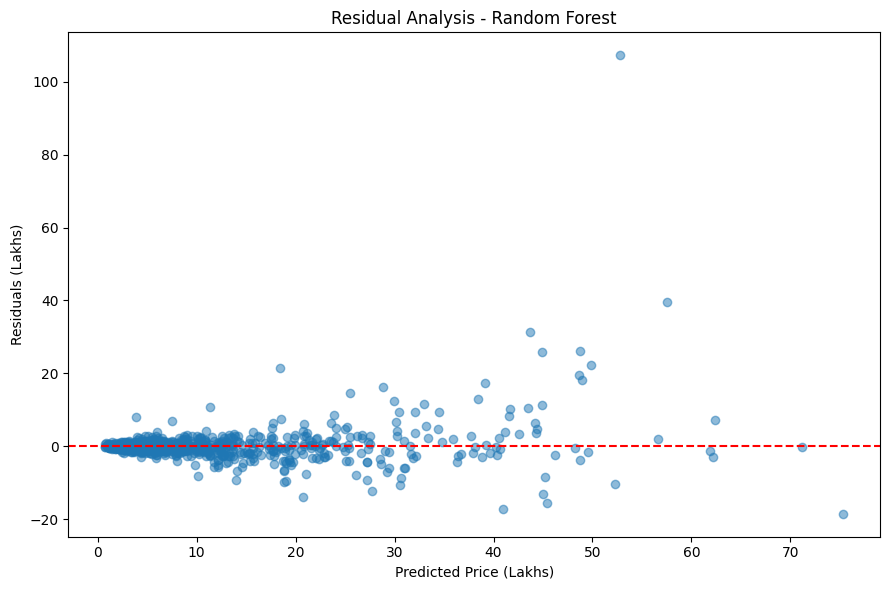

In [65]:
residuals = y_test - y_pred_rf

plt.figure(figsize=(9, 6))

plt.scatter(y_pred_rf, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price (Lakhs)")
plt.ylabel("Residuals (Lakhs)")
plt.title("Residual Analysis - Random Forest")

plt.tight_layout()
plt.show()

### Residual Analysis - Observations

1. The model produces relatively smaller prediction errors for many budget and mid-range cars.

2. Residuals become more widely spread as predicted prices increase.

3. Most large positive residuals occur for expensive vehicles, indicating that the model tends to underestimate their actual prices.

4. Some high-value vehicles have very large prediction errors, exceeding ₹100 lakhs.

5. The model's predictions rarely reach the highest actual price values in the testing dataset.

6. This limitation may be related to the limited representation of expensive luxury cars in the training dataset.

Overall, the model performs better for commonly represented price ranges but struggles with high-value luxury vehicles.

In [66]:
# Create a DataFrame for error analysis
error_df = pd.DataFrame({
    'Actual_Price': y_test,
    'Predicted_Price': y_pred_rf
})

# Calculate absolute prediction error
error_df['Absolute_Error'] = abs(
    error_df['Actual_Price'] - error_df['Predicted_Price']
)

# Divide cars into price segments
bins = [0, 5, 15, 30, float('inf')]

labels = ['Budget (0-5L)', 'Mid-range (5-15L)',
          'Premium (15-30L)', 'Luxury (30L+)']

error_df['Price_Category'] = pd.cut(
    error_df['Actual_Price'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

error_df.head()

,Actual_Price,Predicted_Price,Absolute_Error,Price_Category
1315,5.75,5.454100,0.295900,Mid-range (5-15L)
5825,5.75,5.816550,0.066550,Mid-range (5-15L)
1744,8.00,7.571833,0.428167,Mid-range (5-15L)
1860,5.90,5.126900,0.773100,Mid-range (5-15L)
1559,3.81,4.160400,0.350400,Budget (0-5L)


In [67]:
category_analysis = error_df.groupby(
    'Price_Category',
    observed=False
).agg(
    Car_Count=('Actual_Price', 'count'),
    MAE=('Absolute_Error', 'mean'),
    Average_Actual_Price=('Actual_Price', 'mean')
).round(2)

category_analysis

,Car_Count,MAE,Average_Actual_Price
Price_Category,,,
Budget (0-5L),533,0.53,3.16
Mid-range (5-15L),484,1.16,8.08
Premium (15-30L),120,2.89,21.49
Luxury (30L+),67,9.48,48.14


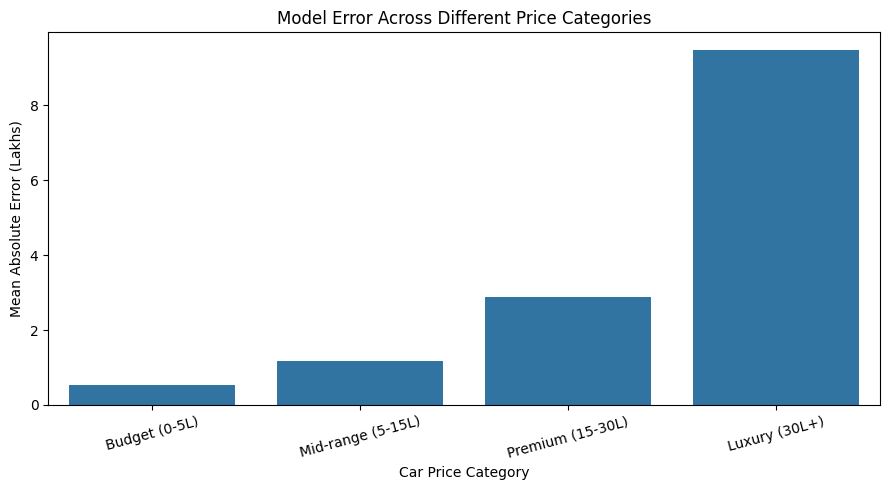

In [68]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x='Price_Category',
    y='MAE'
)

plt.title('Model Error Across Different Price Categories')
plt.xlabel('Car Price Category')
plt.ylabel('Mean Absolute Error (Lakhs)')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Error Analysis by Price Range - Observations

- The model achieved its lowest MAE of ₹0.53 lakhs for budget cars.
- For mid-range cars, the MAE increased to ₹1.16 lakhs.
- Premium cars showed a higher MAE of ₹2.89 lakhs.
- Luxury cars had the highest MAE of ₹9.48 lakhs.
- Prediction errors generally increased with the actual price range.
- The luxury category contained only 67 testing samples, indicating limited representation compared to budget and mid-range vehicles.

The analysis shows that the Random Forest model performs better for budget and mid-range vehicles but struggles with expensive luxury cars.

# Saving the trained Random Forest model and its preprocessing objects

In [69]:
import joblib
import os

# Create models directory if it doesn't exist
os.makedirs('../models', exist_ok=True)

# Store model and preprocessing objects together
model_bundle = {
    'model': rf_model,
    'numeric_imputer': numeric_imputer,
    'categorical_imputer': categorical_imputer,
    'encoder': encoder,
    'numeric_features': numeric_features,
    'categorical_features': categorical_features
}

# Save the complete bundle
joblib.dump(model_bundle, '../models/car_price_model.pkl')

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!


In [70]:

import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

# Load saved model bundle
loaded_bundle = joblib.load('../models/car_price_model.pkl')

# Extract trained model
loaded_model = loaded_bundle['model']

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test_processed)

# Evaluate predictions
print("MAE:", mean_absolute_error(y_test, loaded_predictions))
print("R2 Score:", r2_score(y_test, loaded_predictions))

# Compare with original model predictions
print(
    "Predictions match:",
    np.allclose(y_pred_rf, loaded_predictions)
)

MAE: 1.5133888222789116
R2 Score: 0.8573679176573074
Predictions match: True


### Testing the Model with New Car Details

In [74]:
# Create sample input for a new car

new_car = pd.DataFrame([{
    'Year': 2020,
    'Kilometers_Driven': 35000,
    'Mileage': 18.5,
    'Engine': 1197,
    'Power': 82,
    'Seats': 5,
    'Location': 'Kochi',
    'Fuel_Type': 'Petrol',
    'Transmission': 'Manual',
    'Owner_Type': 'First',
    'Brand': 'Hyundai'
}])

# Apply the saved preprocessing objects

numeric_data = loaded_bundle['numeric_imputer'].transform(
    new_car[numeric_features]
)

categorical_data = loaded_bundle['categorical_imputer'].transform(
    new_car[categorical_features]
)

encoded_data = loaded_bundle['encoder'].transform(
    categorical_data
)

# Combine numerical and encoded categorical features

processed_car = np.hstack([
    numeric_data,
    encoded_data
])

# Predict car price

predicted_price = loaded_model.predict(processed_car)

print(f"Estimated Car Price: ₹{predicted_price[0]:.2f} Lakhs")

Estimated Car Price: ₹6.79 Lakhs


In [75]:
import sys

sys.path.append('../src')

from preprocessing import preprocess_data

# Load original raw dataset
raw_df = pd.read_csv('../data/raw/train-data.csv')

# Apply preprocessing
test_clean_df = preprocess_data(raw_df)

# Remove the suspicious Porsche record
test_clean_df = test_clean_df.drop(index=3132)

print("Processed Dataset Shape:", test_clean_df.shape)
print("\nMissing Values:")
print(test_clean_df.isnull().sum())

Processed Dataset Shape: (6018, 13)

Missing Values:
Name                   0
Location               0
Year                   0
Kilometers_Driven      0
Fuel_Type              0
Transmission           0
Owner_Type             0
Mileage               70
Engine                36
Power                143
Seats                 43
Price                  0
Brand                  0
dtype: int64


In [76]:
import sys
sys.path.append('../src')

from predict import predict_car_price

new_car = {
    'Year': 2020,
    'Kilometers_Driven': 35000,
    'Mileage': 18.5,
    'Engine': 1197,
    'Power': 82,
    'Seats': 5,
    'Location': 'Kochi',
    'Fuel_Type': 'Petrol',
    'Transmission': 'Manual',
    'Owner_Type': 'First',
    'Brand': 'Hyundai'
}

price = predict_car_price(new_car)

print(f"Estimated Car Price: ₹{price:.2f} Lakhs")

Estimated Car Price: ₹6.79 Lakhs
